In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
DATASET_PATH = PROJECT_ROOT / "data" / "raw"
RATING_PATH = DATASET_PATH / "ratings.csv"

ratings = pd.read_csv(
    RATING_PATH, 
    encoding="latin-1"
)

ratings["timestamp"] = pd.to_datetime(ratings["timestamp"], unit="s")

In [13]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,2000-07-30 18:45:03
1,1,3,4.0,2000-07-30 18:20:47
2,1,6,4.0,2000-07-30 18:37:04
3,1,47,5.0,2000-07-30 19:03:35
4,1,50,5.0,2000-07-30 18:48:51


In [15]:
print("Размер таблицы:", ratings.shape)
print("\nТипы данных:")
print(ratings.dtypes)

print("\nПропуски:")
print(ratings.isna().sum())

print("\nКоличество дубликатов:")
print(ratings.duplicated(["userId", "movieId"]).sum())

print("\nПериод оценок:")
print(ratings["timestamp"].min(), "—", ratings["timestamp"].max())

print("\nКоличество пользователей:", ratings["userId"].nunique())
print("Количество фильмов:", ratings["movieId"].nunique())

Размер таблицы: (100836, 4)

Типы данных:
userId               int64
movieId              int64
rating             float64
timestamp    datetime64[s]
dtype: object

Пропуски:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Количество дубликатов:
0

Период оценок:
1996-03-29 18:36:55 — 2018-09-24 14:27:30

Количество пользователей: 610
Количество фильмов: 9724


rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


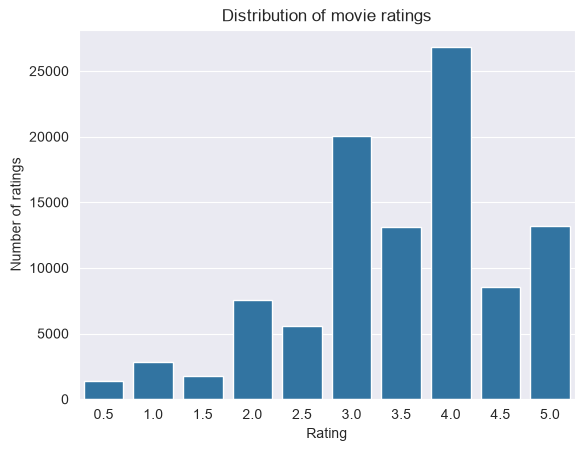

In [16]:
print(ratings["rating"].value_counts().sort_index())

sns.countplot(data=ratings, x="rating")
plt.title("Distribution of movie ratings")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.show()

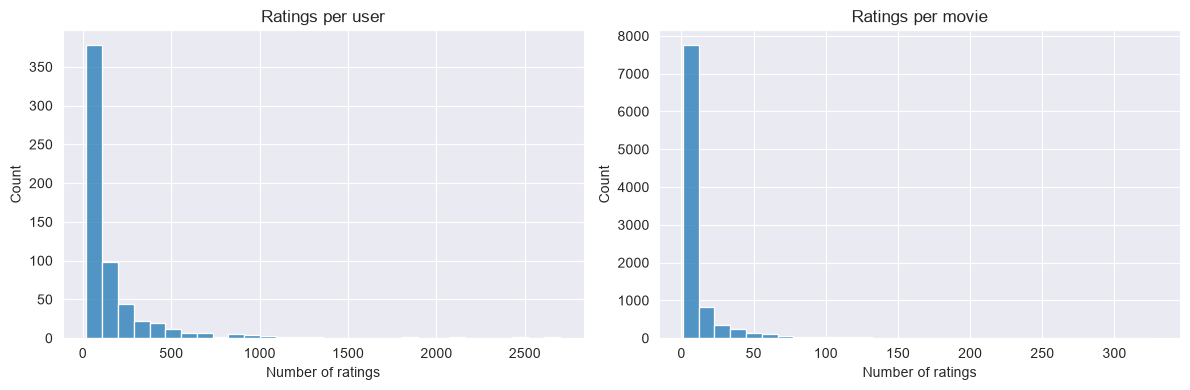

In [17]:
user_activity = ratings.groupby("userId").size()
movie_popularity = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(user_activity, bins=30, ax=axes[0])
axes[0].set_title("Ratings per user")
axes[0].set_xlabel("Number of ratings")

sns.histplot(movie_popularity, bins=30, ax=axes[1])
axes[1].set_title("Ratings per movie")
axes[1].set_xlabel("Number of ratings")

plt.tight_layout()
plt.show()

In [18]:
ratings = ratings.sort_values(
    ["userId", "timestamp", "movieId"]
).reset_index(drop=True)

train_parts = []
test_parts = []

for user_id, user_ratings in ratings.groupby("userId", sort=False):
    split_idx = int(len(user_ratings) * 0.8)

    train_parts.append(user_ratings.iloc[:split_idx])
    test_parts.append(user_ratings.iloc[split_idx:])

train = pd.concat(train_parts).reset_index(drop=True)
test = pd.concat(test_parts).reset_index(drop=True)

print(f"Train: {len(train):,} оценок")
print(f"Test:  {len(test):,} оценок")
print(f"Доля test: {len(test) / len(ratings):.1%}")

Train: 80,419 оценок
Test:  20,417 оценок
Доля test: 20.2%


In [20]:
assert len(train) + len(test) == len(ratings)
assert train["userId"].nunique() == ratings["userId"].nunique()
assert test["userId"].nunique() == ratings["userId"].nunique()

print("Пользователи только в test:",
      len(set(test["userId"]) - set(train["userId"])))

print("Фильмы в test, которых нет в train:",
      len(set(test["movieId"]) - set(train["movieId"])))

Пользователи только в test: 0
Фильмы в test, которых нет в train: 1494


In [21]:
POSITIVE_THRESHOLD = 4

train_positive = train[train["rating"] >= POSITIVE_THRESHOLD].copy()
test_positive = test[test["rating"] >= POSITIVE_THRESHOLD].copy()

print("Положительных примеров в train:", len(train_positive))
print("Положительных примеров в test:", len(test_positive))
print(
    "Доля положительных оценок в test:",
    f"{len(test_positive) / len(test):.1%}"
)

Положительных примеров в train: 39071
Положительных примеров в test: 9509
Доля положительных оценок в test: 46.6%


In [22]:
from datetime import datetime

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

run_id = datetime.now().strftime("%Y%m%d_%H%M%S")

train_path = PROCESSED_DIR / f"train_{run_id}.csv"
test_path = PROCESSED_DIR / f"test_{run_id}.csv"

train.to_csv(train_path, index=False)
test.to_csv(test_path, index=False)

print("Выборки сохранены:")
print(f"Train: {train_path}")
print(f"Test:  {test_path}")
print(f"Размер train: {train.shape}")
print(f"Размер test:  {test.shape}")

Выборки сохранены:
Train: C:\IT\movie-recommender-pytorch\data\processed\train_20261020_161901.csv
Test:  C:\IT\movie-recommender-pytorch\data\processed\test_20261020_161901.csv
Размер train: (80419, 4)
Размер test:  (20417, 4)
